In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
e_commerce=pd.read_csv("ecommerce_sales_data.csv")

In [3]:
e_commerce.head()

,Order Date,Product Name,Category,Region,Quantity,Sales,Profit
0,2024-12-31,Printer,Office,North,4,3640,348.93
1,2022-11-27,Mouse,Accessories,East,7,1197,106.53
2,2022-05-11,Tablet,Electronics,South,5,5865,502.73
3,2024-03-16,Mouse,Accessories,South,2,786,202.87
4,2022-09-10,Mouse,Accessories,West,1,509,103.28


In [4]:
e_commerce.tail()

,Order Date,Product Name,Category,Region,Quantity,Sales,Profit
3495,2023-02-15,Monitor,Accessories,North,4,4064,771.16
3496,2022-09-18,Monitor,Accessories,East,1,1117,119.89
3497,2022-04-12,Laptop,Electronics,South,4,260,66.02
3498,2022-01-18,Printer,Office,South,3,222,50.28
3499,2024-11-01,Smartwatch,Electronics,East,9,10530,1777.32


In [5]:
e_commerce.shape
#rows and columns (3500, 7)

(3500, 7)

In [6]:
e_commerce.size
# total number elements 24500

24500

In [7]:
e_commerce.columns


Index(['Order Date', 'Product Name', 'Category', 'Region', 'Quantity', 'Sales',
       'Profit'],
      dtype='object')

In [8]:
e_commerce.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3500 entries, 0 to 3499
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Order Date    3500 non-null   object 
 1   Product Name  3500 non-null   object 
 2   Category      3500 non-null   object 
 3   Region        3500 non-null   object 
 4   Quantity      3500 non-null   int64  
 5   Sales         3500 non-null   int64  
 6   Profit        3500 non-null   float64
dtypes: float64(1), int64(2), object(4)
memory usage: 191.5+ KB


In [9]:
e_commerce["Order Date"]=pd.to_datetime(e_commerce["Order Date"], errors="coerce")
#convert  "Order Date" object into Datetime dtype

In [10]:
e_commerce.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3500 entries, 0 to 3499
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   Order Date    3500 non-null   datetime64[ns]
 1   Product Name  3500 non-null   object        
 2   Category      3500 non-null   object        
 3   Region        3500 non-null   object        
 4   Quantity      3500 non-null   int64         
 5   Sales         3500 non-null   int64         
 6   Profit        3500 non-null   float64       
dtypes: datetime64[ns](1), float64(1), int64(2), object(3)
memory usage: 191.5+ KB


In [11]:
e_commerce.describe()

,Order Date,Quantity,Sales,Profit
count,3500,3500.000000,3500.000000,3500.000000
mean,2023-07-13 00:53:53.828571648,4.931714,3047.966000,527.047203
min,2022-01-01 00:00:00,1.000000,51.000000,6.970000
25%,2022-10-16 18:00:00,3.000000,1049.500000,158.695000
50%,2023-07-21 12:00:00,5.000000,2350.500000,361.070000
75%,2024-04-16 06:00:00,7.000000,4537.000000,729.125000
max,2024-12-31 00:00:00,9.000000,10782.000000,2946.930000
std,NaN,2.575895,2440.213237,504.139732


In [12]:
# Checking outliers
Q1 = e_commerce["Sales"].quantile(0.25)
Q3 = e_commerce["Sales"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = e_commerce[
    (e_commerce["Sales"] < lower_limit) |
    (e_commerce["Sales"] > upper_limit)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)
print("Number of outliers:", len(outliers))

outliers

Q1: 1049.5
Q3: 4537.0
IQR: 3487.5
Lower Limit: -4181.75
Upper Limit: 9768.25
Number of outliers: 35


,Order Date,Product Name,Category,Region,Quantity,Sales,Profit
32,2023-04-09,Laptop,Electronics,North,9,10773,1907.36
147,2022-10-23,Keyboard,Accessories,West,9,10035,1486.30
153,2024-08-08,Monitor,Accessories,North,9,10530,2387.63
267,2024-01-25,Tablet,Electronics,East,9,10188,2165.78
293,2023-08-08,Monitor,Accessories,North,9,10458,2799.48
379,2022-05-09,Printer,Office,West,9,10656,961.30
455,2023-12-29,Camera,Electronics,West,9,9972,2566.01
846,2024-05-14,Camera,Electronics,West,9,10143,1690.66
977,2024-01-05,Laptop,Electronics,West,9,9783,2347.49
1064,2022-09-15,Keyboard,Accessories,East,9,9810,549.46


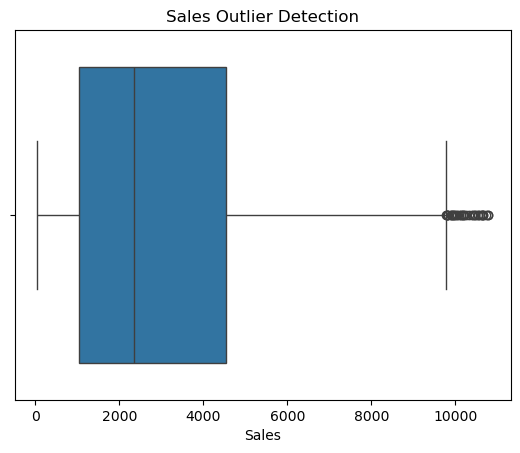

In [13]:
# Visualize outlier using boxplot
sns.boxplot(x=e_commerce["Sales"])
plt.title("Sales Outlier Detection")
plt.xlabel("Sales")
plt.show()

In [14]:
#Step 1: calculate Lower aur Upper limits calculate 
Q1 = e_commerce["Sales"].quantile(0.25)
Q3 = e_commerce["Sales"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)

Lower limit: -4181.75
Upper limit: 9768.25


In [15]:
# step 2 Clipping apply 
e_commerce["Sales_Capped"] = e_commerce["Sales"].clip(
    lower=lower_limit,
    upper=upper_limit
)

In [16]:
# step 3 Checkhow much outliers are reduced
outlier_mask = (
    (e_commerce["Sales"] < lower_limit) |
    (e_commerce["Sales"] > upper_limit)
)

print("Total outliers:", outlier_mask.sum())
print("Values capped:", 
      (e_commerce["Sales"] != e_commerce["Sales_Capped"]).sum())

Total outliers: 35
Values capped: 35


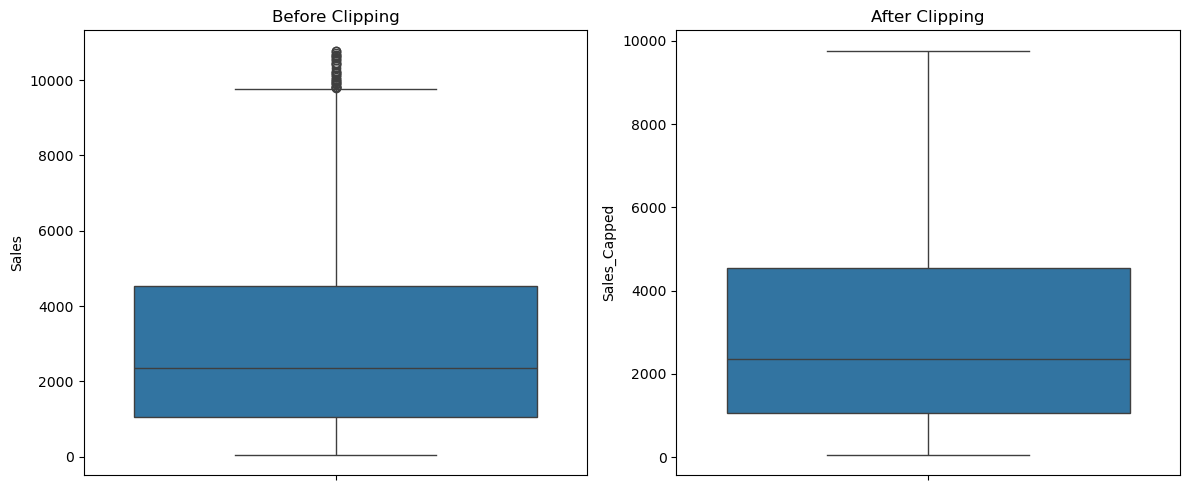

In [17]:
# step 4 Before aur after visualize
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(y=e_commerce["Sales"], ax=axes[0])
axes[0].set_title("Before Clipping")

sns.boxplot(y=e_commerce["Sales_Capped"], ax=axes[1])
axes[1].set_title("After Clipping")

plt.tight_layout()
plt.show()

In [18]:



# DATA PROFILING 





In [19]:
# check missing values
e_commerce.isnull().sum()
# No misiing values

Order Date      0
Product Name    0
Category        0
Region          0
Quantity        0
Sales           0
Profit          0
Sales_Capped    0
dtype: int64

In [20]:
# check Duplicate Transiction
e_commerce.duplicated().sum()
# No duplicate tranication

np.int64(0)

In [21]:
# Checck Unique Values
e_commerce["Category"].unique()

array(['Office', 'Accessories', 'Electronics'], dtype=object)

In [22]:
 e_commerce["Region"].unique() 

array(['North', 'East', 'South', 'West'], dtype=object)

In [23]:
# Handiling Missing Values
# 1. Remove invalid records. 
# but before that we have to label column 1 with row_id

In [24]:
# Make index Column
e_commerce.reset_index(inplace=True)

In [25]:
# Change column name
e_commerce.rename(columns={"index": "Row_ID"}, inplace=True)

In [26]:
e_commerce.head()

,Row_ID,Order Date,Product Name,Category,Region,Quantity,Sales,Profit,Sales_Capped
0,0,2024-12-31,Printer,Office,North,4,3640,348.93,3640.0
1,1,2022-11-27,Mouse,Accessories,East,7,1197,106.53,1197.0
2,2,2022-05-11,Tablet,Electronics,South,5,5865,502.73,5865.0
3,3,2024-03-16,Mouse,Accessories,South,2,786,202.87,786.0
4,4,2022-09-10,Mouse,Accessories,West,1,509,103.28,509.0


In [27]:
# Remove invalid_record
invalid_records = e_commerce[
    e_commerce["Order Date"].isna() |
    e_commerce["Product Name"].isna() |
    e_commerce["Category"].isna() |
    e_commerce["Region"].isna() |
    e_commerce["Quantity"].isna() |
    e_commerce["Sales"].isna() |
    e_commerce["Profit"].isna()
]

print("Invalid records:", len(invalid_records))
invalid_records.head()

# is na is used nan value present or not
# - True = value missing 
# - False = value available

Invalid records: 0


,Row_ID,Order Date,Product Name,Category,Region,Quantity,Sales,Profit,Sales_Capped


In [28]:
# Replace categorial column with unknows
cat_cols = ["Product Name", "Category", "Region"]

e_commerce[cat_cols] = e_commerce[cat_cols].fillna("Unknown")


In [29]:
print(e_commerce[cat_cols].isnull().sum())

Product Name    0
Category        0
Region          0
dtype: int64


In [30]:
# Investigate missing financial values. 
financial_cols = ["Sales", "Profit"]

print(e_commerce[financial_cols].isnull().sum())

Sales     0
Profit    0
dtype: int64


In [31]:
# see Missing values rows
missing_financial = e_commerce[
    e_commerce[financial_cols].isnull().any(axis=1)
]

missing_financial

,Row_ID,Order Date,Product Name,Category,Region,Quantity,Sales,Profit,Sales_Capped


In [32]:
print(
    e_commerce[financial_cols]
    .isnull()
    .mean()
    .mul(100) #multiply by 100.  yahan .mul(100) use kiya kyunki humein missing financial values ka percentage (%) nikalna hai.
)

Sales     0.0
Profit    0.0
dtype: float64


In [33]:
# chek data types of sales and profit
print(e_commerce[financial_cols].dtypes)

Sales       int64
Profit    float64
dtype: object


In [34]:
# Remove duplicates

e_commerce.duplicated().sum()
# Ṭhere is no duplicate if its exist then we drop the duplicate

np.int64(0)

In [35]:
# Convert Numeric Columns'
e_commerce["Sales"]=pd.to_numeric(e_commerce["Sales"])

In [36]:
e_commerce["Profit"]=pd.to_numeric(e_commerce["Profit"])

In [37]:
e_commerce["Quantity"]=pd.to_numeric(e_commerce["Quantity"])

In [38]:
e_commerce.dtypes

Row_ID                   int64
Order Date      datetime64[ns]
Product Name            object
Category                object
Region                  object
Quantity                 int64
Sales                    int64
Profit                 float64
Sales_Capped           float64
dtype: object

In [39]:
# Quantity Validation 


# Negetive Quantity
negetive_quantity=e_commerce[e_commerce["Quantity"]<0]
print("Negetive_quantity",len(negetive_quantity))

Negetive_quantity 0


In [40]:
# Zero quantity
zero_quantity=e_commerce[e_commerce["Quantity"]==0]
print("zero_quantity",len(zero_quantity))

zero_quantity 0


In [41]:
#unusually large Quantity
large_quantity=e_commerce[e_commerce["Quantity"]>upper_limit]
print("large_quantity",len(large_quantity))

large_quantity 0


In [42]:
# Sales Validation

# negetive_sales
negetive_sales=e_commerce[e_commerce["Sales"]<0]
print("Negetive_sales",len(negetive_sales))

Negetive_sales 0


In [43]:
# Zero Sales
zero_sales=e_commerce[e_commerce["Sales"]==0]
print("zero_sales",len(zero_sales))

zero_sales 0


In [44]:
# Extream high sales
Extream_high_sales=e_commerce[e_commerce["Sales"]>9768]
print("Extream_high_sales",len(Extream_high_sales))

Extream_high_sales 35


In [45]:
large_sales=e_commerce[e_commerce["Sales"]>upper_limit]
large_sales[["Product Name","Category","Region","Quantity","Sales","Profit"]]
print("upper_limit",upper_limit)
print("maximum_sales",[e_commerce["Sales"].max()])
print("Extrem_high_sales",len(large_sales))

upper_limit 9768.25
maximum_sales [10782]
Extrem_high_sales 35


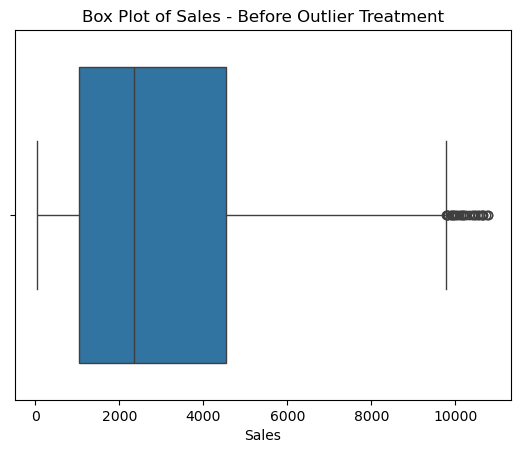

In [46]:

sns.boxplot(x=e_commerce["Sales"])
plt.title("Box Plot of Sales - Before Outlier Treatment")
plt.xlabel("Sales")
plt.show()


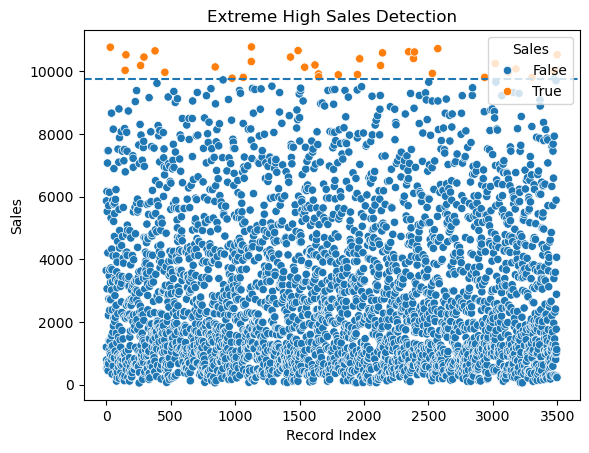

In [47]:

sns.scatterplot(
    x=e_commerce.index,
    y=e_commerce["Sales"],
    hue=e_commerce["Sales"] > upper_limit
)

plt.axhline(upper_limit, linestyle="--")
plt.title("Extreme High Sales Detection")
plt.xlabel("Record Index")
plt.ylabel("Sales")
plt.show()

In [48]:

e_commerce["Sales_Capped"] = e_commerce["Sales"].clip(upper=upper_limit)

# Check the results
print("Original maximum:", e_commerce["Sales"].max())
print("Capped maximum:", e_commerce["Sales_Capped"].max())

e_commerce[["Sales", "Sales_Capped"]].sort_values(
    by="Sales", ascending=False
).head(10)


Original maximum: 10782
Capped maximum: 9768.25


,Sales,Sales_Capped
1127,10782,9768.25
32,10773,9768.25
2573,10728,9768.25
1489,10665,9768.25
379,10656,9768.25
2347,10629,9768.25
2392,10620,9768.25
2144,10593,9768.25
3499,10530,9768.25
153,10530,9768.25


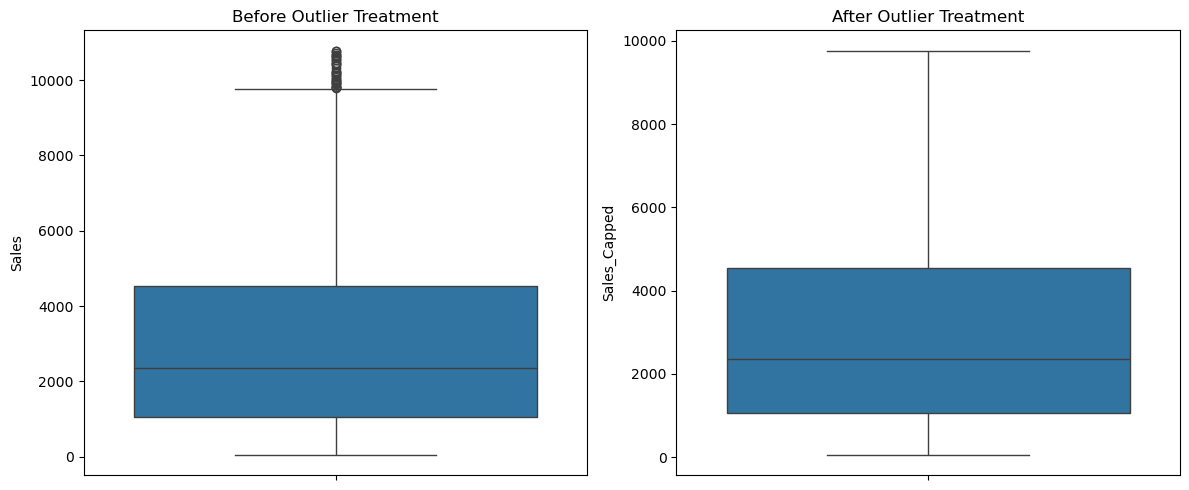

In [49]:

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(y=e_commerce["Sales"], ax=axes[0])
axes[0].set_title("Before Outlier Treatment")

sns.boxplot(y=e_commerce["Sales_Capped"], ax=axes[1])
axes[1].set_title("After Outlier Treatment")

plt.tight_layout()
plt.show()


In [50]:
# VALIDATE CLIPPED DATA
print("Null values:", e_commerce["Sales_Capped"].isnull().sum())
print("Maximum before:", e_commerce["Sales"].max())
print("Maximum after:", e_commerce["Sales_Capped"].max())
print("Values capped:", (e_commerce["Sales"] > upper_limit).sum())


Null values: 0
Maximum before: 10782
Maximum after: 9768.25
Values capped: 35


In [51]:

# PROFIT VALIDATION



In [52]:
negetive_Profit=e_commerce[e_commerce["Profit"]<0]
print("Negetive_Profit",len(negetive_Profit))

Negetive_Profit 0


In [53]:
Zero_profit=e_commerce[e_commerce["Profit"]==0]
print("Zero_profit",len(Zero_profit))

Zero_profit 0


In [54]:

# FEATURE ENGINEERING 



In [55]:
# Year
e_commerce["Order Date"] = pd.to_datetime(
    e_commerce["Order Date"],
    errors="coerce"
)

e_commerce["Year"] = e_commerce["Order Date"].dt.year

In [56]:
# Month Number
e_commerce["Month"]=e_commerce["Order Date"].dt.month

In [57]:
# Month Name
e_commerce["Month Name"]=e_commerce["Order Date"].dt.month_name()
e_commerce["Month Name"]

0        December
1        November
2             May
3           March
4       September
          ...    
3495     February
3496    September
3497        April
3498      January
3499     November
Name: Month Name, Length: 3500, dtype: object

In [58]:
e_commerce["Quarter"]=e_commerce["Order Date"].dt.quarter
e_commerce["Quarter"]

0       4
1       4
2       2
3       1
4       3
       ..
3495    1
3496    3
3497    2
3498    1
3499    4
Name: Quarter, Length: 3500, dtype: int32

In [59]:
# Profit Margin
e_commerce["Profit Margin"]=(e_commerce["Profit"] / e_commerce["Sales"]) * 100
e_commerce["Profit Margin"]

0        9.585989
1        8.899749
2        8.571697
3       25.810433
4       20.290766
          ...    
3495    18.975394
3496    10.733214
3497    25.392308
3498    22.648649
3499    16.878632
Name: Profit Margin, Length: 3500, dtype: float64

In [60]:


# EXPLORATORY DATA ANALYSIS — EDA 
# EDA is the process of exploring the dataset to discover patterns, relationships, and unusual behavior. 
# The analysis will cover: 
# 1.	Overall sales performance 
# 2.	Time-based trends 
# 3.	Product performance 
# 4.	Category performance 
# 5.	Regional performance 
# 6.	Profitability 



In [61]:
# Overall Sales Analysis

In [62]:
# Total sales
total_sales=e_commerce["Sales"].sum()
total_sales

np.int64(10667881)

In [63]:
# Total Profit
total_profit=e_commerce["Profit"].sum()
total_profit

np.float64(1844665.21)

In [64]:
# Total_quantity_sold
total_quantity=e_commerce["Quantity"].sum()
total_quantity

np.int64(17261)

In [65]:
# Total Transication
total_transactions=len(e_commerce)
total_transactions

3500

In [66]:
# Average Transication
avg_transication_value=(total_sales / total_transactions)
avg_transication_value

np.float64(3047.966)

In [67]:


# Monthly  Sales Trend Transactions
# Objective 
# Identify monthly fluctuations and seasonal sales patterns. 




In [68]:
# Calculate Month sales
monthly_sales=(e_commerce.groupby("Month")["Sales"].sum().reset_index())
monthly_sales

,Month,Sales
0,1,967614
1,2,702414
2,3,939614
3,4,821876
4,5,1034687
5,6,839805
6,7,844940
7,8,924939
8,9,885546
9,10,892269


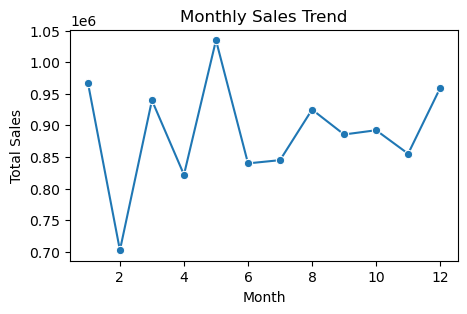

In [69]:
# Visualize Monthly Sales 
plt.figure(figsize=(5, 3)) 
 
sns.lineplot(data=monthly_sales,x="Month",y="Sales",marker="o" 
) 
 
plt.title("Monthly Sales Trend") 
plt.xlabel("Month") 
plt.ylabel("Total Sales") 
plt.show() 


In [70]:
# Business Questions 
# ●	Which month generated the highest sales?  >> May generated the highest sales, with approximately 1.04 million in total sales.
# ●	Which month generated the lowest sales?  >> February generated the lowest sales, with approximately 0.70 million in total sales
# ●	Are there seasonal patterns? > ales fluctuate throughout the year. However, more years of data are needed to confirm a seasonal pattern.
# ●	Are sales increasing over time?  >> No, sales are not consistently increasing over time. They fluctuate from month to month, with a noticeable increase in December. 


In [71]:

# Monthly Profit Analysis


In [72]:
monthly_profit=e_commerce.groupby("Month")["Profit"].sum().reset_index()
monthly_profit


,Month,Profit
0,1,177280.29
1,2,118958.72
2,3,162136.63
3,4,145620.96
4,5,173293.15
5,6,143198.53
6,7,149244.11
7,8,152959.89
8,9,150265.04
9,10,153027.97


In [73]:
# monthly_Sales_profit

monthly_sales_profit = e_commerce.groupby(
    e_commerce["Order Date"].dt.month
)[["Sales", "Profit"]].sum()

print(monthly_sales_profit)


              Sales     Profit
Order Date                    
1            967614  177280.29
2            702414  118958.72
3            939614  162136.63
4            821876  145620.96
5           1034687  173293.15
6            839805  143198.53
7            844940  149244.11
8            924939  152959.89
9            885546  150265.04
10           892269  153027.97
11           855075  144837.79
12           959102  173842.13


In [74]:
print("highest_sales_month",monthly_sales_profit["Sales"].idxmax())
print("highest_profit_month",monthly_sales_profit["Profit"].idxmax())

highest_sales_month 5
highest_profit_month 1


In [75]:

# PRODUCT PERFORMANCE ANALYSIS 



In [76]:
product_sales=(e_commerce.groupby("Product Name")["Sales"].sum().sort_values(ascending=False))

In [77]:
product_sales.head()

Product Name
Camera        1177381
Monitor       1160048
Printer       1094216
Mouse         1074398
Smartphone    1069681
Name: Sales, dtype: int64

In [78]:
product_profit=(e_commerce.groupby("Product Name")["Profit"].sum().sort_values(ascending=False))
product_profit.head()

Product Name
Camera     207630.99
Monitor    202028.17
Mouse      185763.69
Laptop     185756.81
Printer    185394.88
Name: Profit, dtype: float64

In [79]:
product_quantity=(e_commerce.groupby("Product Name")["Quantity"].sum().sort_values(ascending=False))
product_quantity.head()

Product Name
Monitor       1876
Smartwatch    1807
Camera        1795
Mouse         1753
Printer       1734
Name: Quantity, dtype: int64

In [80]:

# CATEGORY ANALYSIS 
# The dataset contains three main categories: 
# ●	Technology 
# ●	Furniture 
# ●	Office Supplies 


In [81]:
# Sales by category
category_sales=(e_commerce.groupby("Category")["Sales"].sum().sort_values(ascending=False))
category_sales.head()

Category
Electronics    5326074
Accessories    4247591
Office         1094216
Name: Sales, dtype: int64

In [82]:
# Profit by Category
category_profit=(e_commerce.groupby("Category")["Profit"].sum().sort_values(ascending=False))
category_profit.head()

Category
Electronics    923185.59
Accessories    736084.74
Office         185394.88
Name: Profit, dtype: float64

In [83]:
# quanity by Catgory
category_quantity=(e_commerce.groupby("Category")["Quantity"].sum().sort_values(ascending=False))
category_quantity.head()

Category
Electronics    8610
Accessories    6917
Office         1734
Name: Quantity, dtype: int64

In [85]:
# Business Questions 
# ●	Which category generates the highest revenue? >> Electronics 5326074
# ●	Which category generates the highest profit?  >> Electronics    923185.59
# ●	Which category sells the highest quantity?    >> Electronics    8610
# ●	Does the highest-sales category also have the highest profit?  >> yes its have


In [86]:

# Regional Analysis


In [87]:
# Sales By Region
region_sales=(e_commerce.groupby("Region")["Sales"].sum().sort_values(ascending=False))
region_sales.head()

Region
West     2844450
East     2675110
South    2659548
North    2488773
Name: Sales, dtype: int64

In [88]:
# Profit by region\
region_profit=(e_commerce.groupby("Region")["Profit"].sum().sort_values(ascending=False))
region_profit.head()

Region
West     495358.73
East     464888.46
South    458103.27
North    426314.75
Name: Profit, dtype: float64

In [89]:
# Quantity by Region
region_quantity=(e_commerce.groupby("Region")["Quantity"].sum().sort_values(ascending=False))
region_quantity.head()

Region
West     4488
South    4361
East     4306
North    4106
Name: Quantity, dtype: int64

In [90]:
# Business Questions 
# ●	Which region generates the highest sales? >>> West     2844450
# ●	Which region generates the highest profit? >>. West     495358.73
# ●	Which region sells the most units? >>>>West
# ●	Are some regions generating high sales but low profit? >> No [Sales high profit high Sales lowe Profit Low]


In [91]:


# REGIONAL CATEGORY ANALYSIS 



In [92]:
# Analyze category performance within each region. 
regional_category_sales = (e_commerce.groupby(["Region", "Category","Profit"])["Sales"] 
      .sum() 
      .reset_index() 
) 
regional_category_sales

,Region,Category,Profit,Sales
0,East,Accessories,10.35,109
1,East,Accessories,11.10,130
2,East,Accessories,17.71,85
3,East,Accessories,22.42,266
4,East,Accessories,27.43,190
...,...,...,...,...
3486,West,Office,1596.88,9280
3487,West,Office,1693.77,6924
3488,West,Office,2017.85,7524
3489,West,Office,2113.06,7072


NameError: name 'office' is not defined

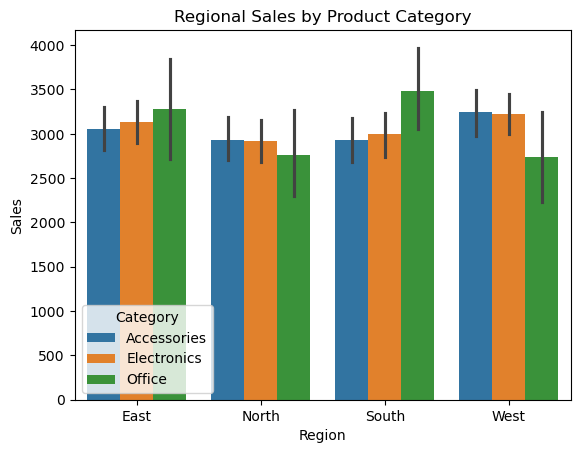

In [93]:
sns.barplot(
    data=regional_category_sales,
    x="Region",
    y="Sales",
    hue="Category"
)

plt.title("Regional Sales by Product Category")
plt.xlabel("Region")


# Which product categories perform best in each region? 
office in south
electronics in  west
accessories in west

In [ ]:

# PROFITABILITY ANALYSIS 
# This is one of the most important sections of the project. 




In [ ]:
# Overall Profit Margin
overall_profit_margin=(e_commerce["Profit"].sum() / e_commerce["Sales"].sum())*100
overall_profit_margin

In [ ]:
# Profit Margin by Category
category_summary=(e_commerce.groupby("Category").agg(
    total_sales=("Sales","sum"),
    total_profit=("Profit","sum")).reset_index())

category_summary["Profit_Margin"]=(category_summary["total_profit"] / category_summary["total_sales"])* 100
category_summary

In [ ]:
# Profit Margin by Region 
region_summary = (e_commerce.groupby("Region") 
      .agg( 
          total_sales=("Sales", "sum"), 
          total_profit=("Profit", "sum") 
      ) 
      .reset_index() 
) 
region_summary["Profit_Margin"] = (region_summary["total_profit"] /     region_summary["total_sales"] 
) * 100 
region_summary

In [ ]:

# HIGH SALES, LOW PROFIT ANALYSIS


In [ ]:
# 25.1 Business Problem 
# Some products may generate substantial revenue but contribute relatively little profit. 
# For example: 
# Product A 
# High Sales 
# Low Profit Margin 
# This may require further investigation into: 
# ●	Pricing 
# ●	Discounts 
# ●	Product costs 
# ●	Shipping expenses 
# ●	Other transaction-level costs, if available 


In [105]:
# PRODUCT LEVEL SUMMARY
product_summary = (
    e_commerce.groupby("Product Name")
      .agg(
          total_sales=("Sales", "sum"),
          total_profit=("Profit", "sum"),
          total_quantity=("Quantity", "sum")
      )
      .reset_index()
)

product_summary["profit_margin"] = (
    product_summary["total_profit"] / product_summary["total_sales"]
) * 100

product_summary.head()

,Product Name,total_sales,total_profit,total_quantity,profit_margin
0,Camera,1177381,207630.99,1795,17.634987
1,Headphones,988638,172478.20,1604,17.446042
2,Keyboard,1024507,175814.68,1684,17.160906
3,Laptop,1005873,185756.81,1658,18.467223
4,Monitor,1160048,202028.17,1876,17.415501


In [ ]:
# Identify High-Sales, Low-Profit Products 
# You must define what high sales and low profit mean. 
# For example: 
# ●	High sales: Above the median product sales 
# ●	Low profit margin: Below the median product profit margin 
# high_sales_threshold = product_summary["Total_Sales"].median() low_margin_threshold = product_summary["Profit_Margin"].median() 
 
# high_sales_low_profit = product_summary[ 
#     (product_summary["Total_Sales"] > high_sales_threshold) & 
#     (product_summary["Profit_Margin"] < low_margin_threshold) 
# ]
# Important 
# The median is only one possible method. You can also use business-defined thresholds or percentiles. 


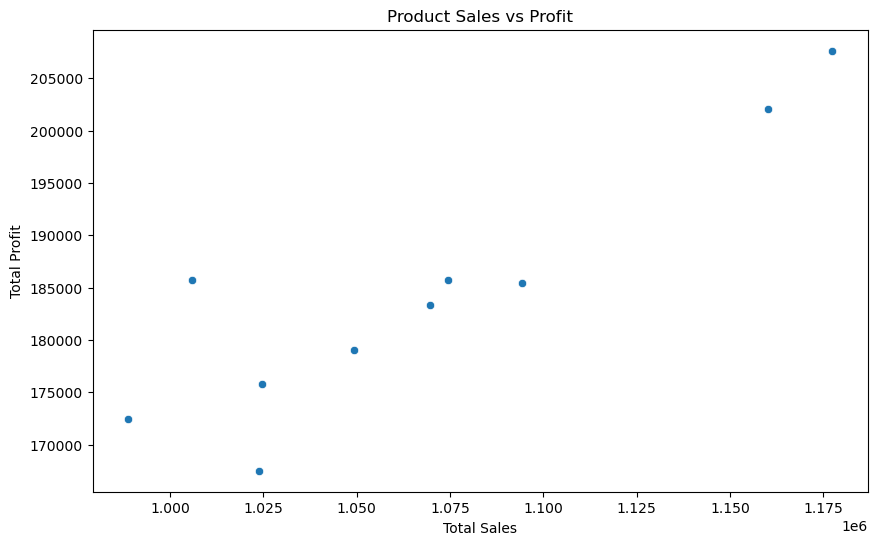

In [106]:
plt.figure(figsize=(10, 6)) 
 
sns.scatterplot( data=product_summary, x="total_sales",y="total_profit" 
) 
 
plt.title("Product Sales vs Profit") 
plt.xlabel("Total Sales") 
plt.ylabel("Total Profit") 
plt.show() 


# ●	Which products generate high sales and high profit? 
# ●	Which products generate high sales but low profit? 
# ●	Which products generate low sales but high profit margins? 


In [107]:
# Step 1: Define "high sales" and "low profit" thresholds (median method)
high_sales_threshold = product_summary["total_sales"].median()
low_margin_threshold = product_summary["profit_margin"].median()

print(f"High sales threshold:  {high_sales_threshold:,.2f}")
print(f"Low margin threshold:  {low_margin_threshold:.2f}%")

# Step 2: Filter products that meet both conditions
high_sales_low_profit = product_summary[
    (product_summary["total_sales"] > high_sales_threshold) &
    (product_summary["profit_margin"] < low_margin_threshold)
].copy()

# Step 3: Sort so the worst offenders appear first
high_sales_low_profit = high_sales_low_profit.sort_values("profit_margin")

print(f"\nProducts found: {len(high_sales_low_profit)}")
print(high_sales_low_profit.head(10))

High sales threshold:  1,059,446.00
Low margin threshold:  17.23%

Products found: 2
  Product Name  total_sales  total_profit  total_quantity  profit_margin
6      Printer      1094216     185394.88            1734      16.943170
7   Smartphone      1069681     183296.97            1617      17.135667


In [ ]:

# Ṣales Vs Profit Analysis


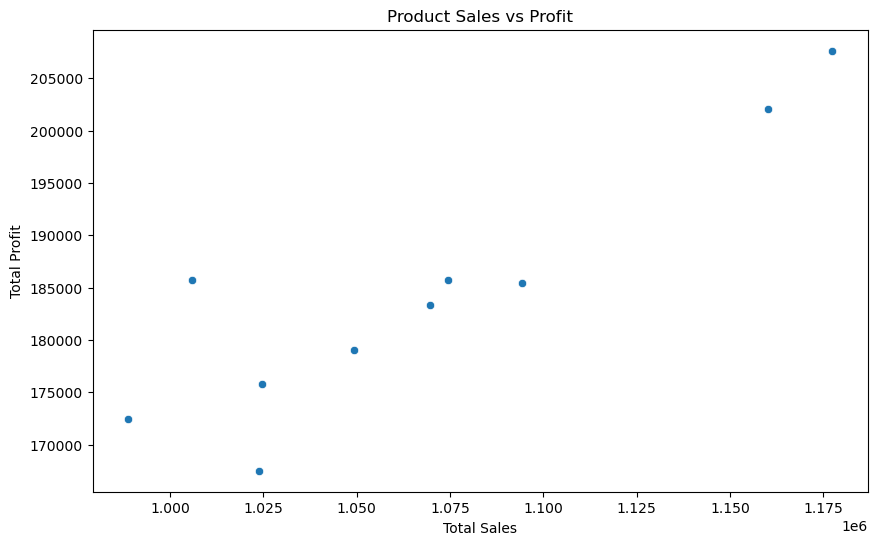

In [108]:
# Create a scatter plot comparing product sales and profit. 
plt.figure(figsize=(10, 6)) 
 
sns.scatterplot(data=product_summary,x="total_sales",y="total_profit" 
) 
plt.title("Product Sales vs Profit") 
plt.xlabel("Total Sales") 
plt.ylabel("Total Profit") 
plt.show() 


# Questions 
# ●	Which products generate high sales and high profit? 
# ●	Which products generate high sales but low profit? 
# ●	Which products generate low sales but high profit margins? 


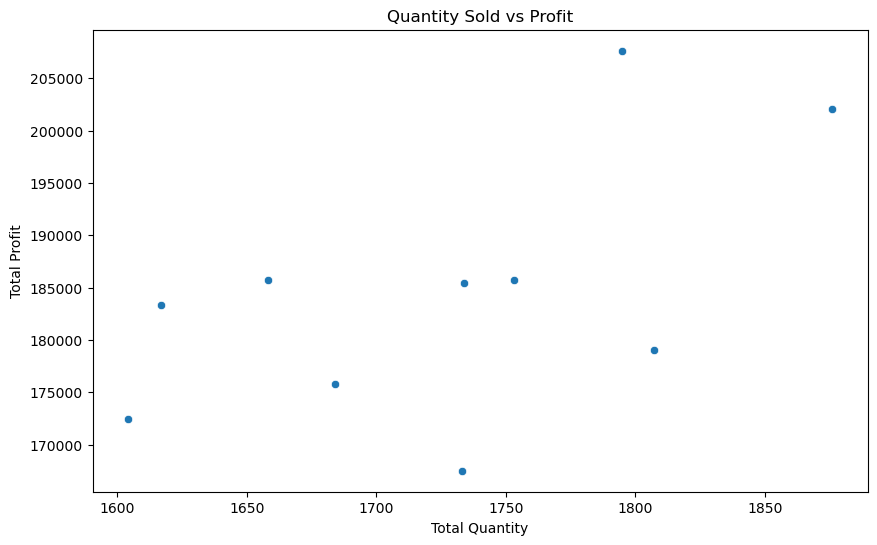

In [109]:
# QUANTITY VS PROFIT ANALYSIS 
# Analyze whether products selling more units necessarily generate more profit. 
plt.figure(figsize=(10, 6)) 
 
sns.scatterplot(data=product_summary,x="total_quantity",y="total_profit" 
) 
plt.title("Quantity Sold vs Profit") 
plt.xlabel("Total Quantity") 
plt.ylabel("Total Profit") 
plt.show() 


In [ ]:


# Statsitical Analysis


In [114]:
# sales stats
e_commerce["Sales"].describe()

count     3500.000000
mean      3047.966000
std       2440.213237
min         51.000000
25%       1049.500000
50%       2350.500000
75%       4537.000000
max      10782.000000
Name: Sales, dtype: float64

In [115]:
# Profit  stats
e_commerce["Profit"].describe()

count    3500.000000
mean      527.047203
std       504.139732
min         6.970000
25%       158.695000
50%       361.070000
75%       729.125000
max      2946.930000
Name: Profit, dtype: float64

In [116]:
# Quantity stats
e_commerce["Quantity"].describe()

count    3500.000000
mean        4.931714
std         2.575895
min         1.000000
25%         3.000000
50%         5.000000
75%         7.000000
max         9.000000
Name: Quantity, dtype: float64

In [ ]:

# Correleation Analysis



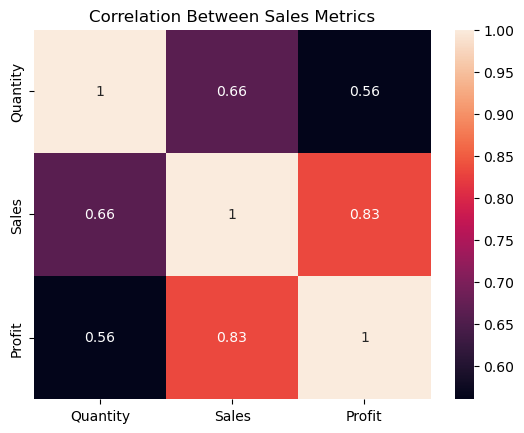

In [118]:
#Analyze relationships between numerical variables. 
e_commerce[["Quantity", "Sales", "Profit"]].corr() 
# Visualize: 
sns.heatmap( 
    e_commerce[["Quantity", "Sales", "Profit"]].corr(),annot=True 
)
 
plt.title("Correlation Between Sales Metrics") 
plt.show() 


In [119]:
e_commerce.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3500 entries, 0 to 3499
Data columns (total 14 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Row_ID         3500 non-null   int64         
 1   Order Date     3500 non-null   datetime64[ns]
 2   Product Name   3500 non-null   object        
 3   Category       3500 non-null   object        
 4   Region         3500 non-null   object        
 5   Quantity       3500 non-null   int64         
 6   Sales          3500 non-null   int64         
 7   Profit         3500 non-null   float64       
 8   Sales_Capped   3500 non-null   float64       
 9   Year           3500 non-null   int32         
 10  Month          3500 non-null   int32         
 11  Month Name     3500 non-null   object        
 12  Quarter        3500 non-null   int32         
 13  Profit Margin  3500 non-null   float64       
dtypes: datetime64[ns](1), float64(3), int32(3), int64(3), object(4)
memory u